# Fintech Customer Churn: Statistical Analysis

## 1. Association Between Customer Age and Churn Classification

In [1]:
import numpy as np
from scipy.stats import chi2_contingency

In [2]:
# Observed frequencies: rows represent age bands; columns represent churn categories.

observed = np.array([
    [101, 228],
    [1654, 4058],
    [974, 2617],
    [433, 1249]
])

In [3]:
# Chi-square test of independence between age band and churn classification.

chi2, p_value, dof, expected = chi2_contingency(observed)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

print("\nExpected frequencies:")
print(expected)

Chi-square statistic: 9.395258804989368
Degrees of freedom: 3
P-value: 0.024472137870100597

Expected frequencies:
[[  91.94785222  237.05214778]
 [1596.3712215  4115.6287785 ]
 [1003.60102528 2587.39897472]
 [ 470.07990101 1211.92009899]]


In [4]:
# Calculate Cramér's V to measure the strength of association.

n = observed.sum()

cramers_v = np.sqrt(
    chi2 / (n * min(observed.shape[0] - 1, observed.shape[1] - 1))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.02881683545679773


Age band was significantly associated with the supplied churn classification (χ² = 9.395, df = 3, p = 0.024). However, the association was negligible in magnitude (Cramér's V = 0.029), suggesting that age group has limited standalone explanatory value for customer churn classification.

## 2. Association Between Customer Gender and Churn Classification

In [5]:
import numpy as np
from scipy.stats import chi2_contingency

observed_gender = np.array([
    [1686, 4389],  # Female
    [1474, 3762]   # Male
])

chi2_gender, p_gender, dof_gender, expected_gender = chi2_contingency(
    observed_gender
)

print("Chi-square statistic:", chi2_gender)
print("Degrees of freedom:", dof_gender)
print("P-value:", p_gender)
print("Expected frequencies:\n", expected_gender)

Chi-square statistic: 0.20212362541681417
Degrees of freedom: 1
P-value: 0.6530121496239863
Expected frequencies:
 [[1697.19741844 4377.80258156]
 [1462.80258156 3773.19741844]]


In [6]:
n_gender = observed_gender.sum()

cramers_v_gender = np.sqrt(
    chi2_gender / (
        n_gender * min(
            observed_gender.shape[0] - 1,
            observed_gender.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v_gender)

Cramér's V: 0.004227251028898342


Customer gender showed no statistically significant association with the supplied churn classification (χ² = 0.202, df = 1, p = 0.653). The association was negligible in magnitude (Cramér's V = 0.004), suggesting that gender has very limited standalone value for distinguishing customers by churn classification in this dataset.

Gender alone does not appear to be a useful variable for prioritising customer retention efforts based on these results.

This is an association analysis, not evidence that gender causes or prevents churn.

## 3. Association Between Marital Status and Churn Classification

In [7]:
observed_marital = np.array([
    [1873, 4767],  # Married
    [1231, 3214]   # Not Married
])

chi2_marital, p_marital, dof_marital, expected_marital = chi2_contingency(
    observed_marital
)

print("Chi-square statistic:", chi2_marital)
print("Degrees of freedom:", dof_marital)
print("P-value:", p_marital)
print("Expected frequencies:\n", expected_marital)

Chi-square statistic: 0.3236175935003698
Degrees of freedom: 1
P-value: 0.5694416715240624
Expected frequencies:
 [[1859.31980153 4780.68019847]
 [1244.68019847 3200.31980153]]


In [8]:
n_marital = observed_marital.sum()

cramers_v_marital = np.sqrt(
    chi2_marital / (
        n_marital * min(
            observed_marital.shape[0] - 1,
            observed_marital.shape[1] - 1
        )
    )
)

print("Cramér's V:", cramers_v_marital)

Cramér's V: 0.005403164791210014


Marital status showed no statistically significant association with the supplied churn classification (χ² = 0.324, df = 1, p = 0.569). The association was negligible in magnitude (Cramér's V = 0.005), suggesting that marital status has very limited standalone value for distinguishing customers by churn classification.

In [9]:
from google.colab import files

uploaded = files.upload()

Saving fintech_customer_churn_cleaned.csv to fintech_customer_churn_cleaned.csv


In [11]:
import pandas as pd

df = pd.read_csv("fintech_customer_churn_cleaned.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (11314, 27)


,CIF,Customername,CustSex,Age,CustMaritalStatus,CustLimit,TotalActiveCard,CustVisaCard,CustMastercardCard,FirstDteOpen,...,Trx2024,Trx2025,Counttrx,AvgTrxPerMonth,TotalBillingAmount,AvgBillingAmount,LastTrxDate,MonthsSinceLastTrx,UsagePercent,Churn
0,1,CUSTOMER1,Female,36,Married,13000000,1,1,1,1611,...,482,135,1547,14.88,485133214.0,313596.1306,01/08/2025 16:11,6.0,3731.79,1
1,2,CUSTOMER2,Male,48,Married,45500000,1,0,3,1709,...,109,28,586,586.00,326916371.0,557877.7662,01/08/2025 09:42,6.0,718.50,1
2,3,CUSTOMER3,Female,35,Not Married,21000000,0,0,1,1708,...,129,0,284,284.00,177482982.0,624940.0775,25/10/2024 07:52,16.0,845.16,1
3,4,CUSTOMER4,Male,72,Married,12500000,2,2,3,1003,...,63,30,187,2.20,136399836.4,729410.8901,27/07/2025 09:28,7.0,1091.20,1
4,5,CUSTOMER5,Male,41,Married,30000000,1,0,1,1710,...,89,139,441,441.00,325142140.0,737283.7642,31/07/2025 01:48,7.0,1083.81,1


In [12]:
df.columns.tolist()

['CIF',
 'Customername',
 'CustSex',
 'Age',
 'CustMaritalStatus',
 'CustLimit',
 'TotalActiveCard',
 'CustVisaCard',
 'CustMastercardCard',
 'FirstDteOpen',
 'LastDteOpen',
 'FirstExpDate',
 'LastExpDate',
 'TotalActiveMonths',
 'ActiveYears',
 'Trx2022',
 'Trx2023',
 'Trx2024',
 'Trx2025',
 'Counttrx',
 'AvgTrxPerMonth',
 'TotalBillingAmount',
 'AvgBillingAmount',
 'LastTrxDate',
 'MonthsSinceLastTrx',
 'UsagePercent',
 'Churn']

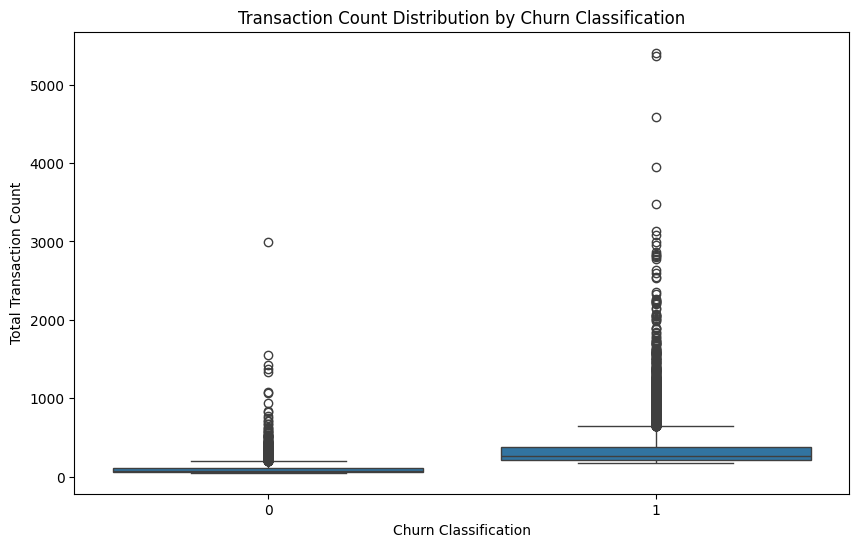

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="Counttrx"
)

plt.title("Transaction Count Distribution by Churn Classification")
plt.xlabel("Churn Classification")
plt.ylabel("Total Transaction Count")
plt.show()

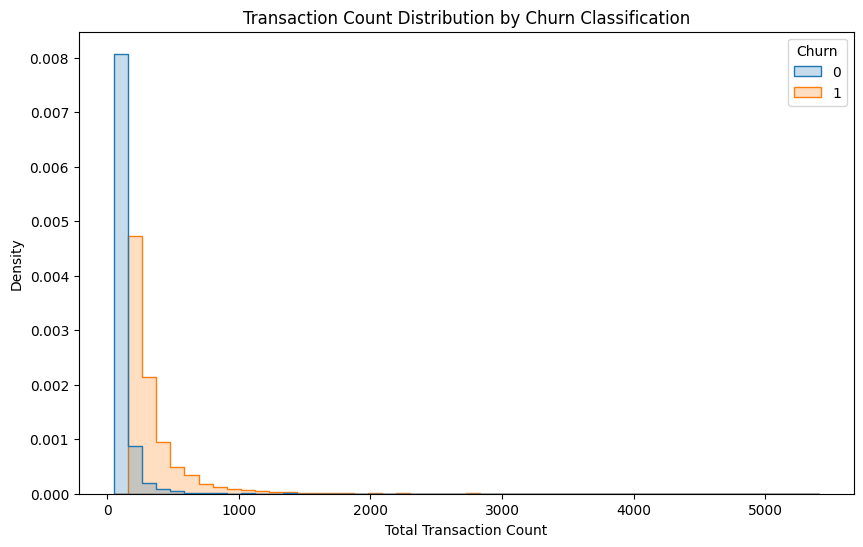

In [14]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Counttrx",
    hue="Churn",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Count Distribution by Churn Classification")
plt.xlabel("Total Transaction Count")
plt.ylabel("Density")
plt.show()

## 4. Transaction Activity Differences Between Churn Groups

In [15]:
from scipy.stats import mannwhitneyu

not_churned = df.loc[df["Churn"] == 0, "Counttrx"]
churned = df.loc[df["Churn"] == 1, "Counttrx"]

u_statistic, p_value = mannwhitneyu(
    not_churned,
    churned,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 1235735.5
P-value: 0.0


In [16]:
n_not_churned = len(not_churned)
n_churned = len(churned)

rank_biserial = 1 - (
    2 * u_statistic /
    (n_not_churned * n_churned)
)

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: 0.9041196783566382


Transaction activity differed significantly between churned and non-churned customers (Mann–Whitney U = 1,235,735.5, p below displayed precision). The rank-biserial correlation was 0.904, indicating an extremely large difference in transaction-count ranks. Customers classified as churned had a median of 262 transactions, compared with 77 among non-churned customers.

In [17]:
from scipy.stats import mannwhitneyu

annual_columns = ["Trx2022", "Trx2023", "Trx2024", "Trx2025"]

for column in annual_columns:
    group_0 = df.loc[df["Churn"] == 0, column]
    group_1 = df.loc[df["Churn"] == 1, column]

    u_stat, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    print(f"\n{column}")
    print("U statistic:", u_stat)
    print("P-value:", p_value)


Trx2022
U statistic: 8797531.0
P-value: 9.130590853130729e-152

Trx2023
U statistic: 3761759.5
P-value: 0.0

Trx2024
U statistic: 1107171.5
P-value: 0.0

Trx2025
U statistic: 1182256.5
P-value: 0.0


In [18]:
annual_effect_sizes = {}

for column in annual_columns:
    group_0 = df.loc[df["Churn"] == 0, column]
    group_1 = df.loc[df["Churn"] == 1, column]

    u_stat, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    effect_size = 1 - (
        2 * u_stat / (len(group_0) * len(group_1))
    )

    annual_effect_sizes[column] = effect_size

    print(f"{column}:")
    print(f"Rank-biserial correlation: {effect_size:.4f}\n")

Trx2022:
Rank-biserial correlation: 0.3174

Trx2023:
Rank-biserial correlation: 0.7081

Trx2024:
Rank-biserial correlation: 0.9141

Trx2025:
Rank-biserial correlation: 0.9083



Annual transaction activity differed significantly between customers classified as churned and non-churned across all four supplied years. The rank-biserial correlation increased from 0.317 in 2022 to 0.708 in 2023, 0.914 in 2024 and 0.908 in 2025. This indicates increasingly pronounced differences in transaction-count ranks between the two groups, particularly from 2023 onward.

In [19]:
from scipy.stats import mannwhitneyu

not_churned = df.loc[
    df["Churn"] == 0, "MonthsSinceLastTrx"
].dropna()

churned = df.loc[
    df["Churn"] == 1, "MonthsSinceLastTrx"
].dropna()

u_stat, p_value = mannwhitneyu(
    not_churned,
    churned,
    alternative="two-sided"
)

print("U statistic:", u_stat)
print("P-value:", p_value)

U statistic: 21585032.0
P-value: 0.0


In [20]:
n1 = len(not_churned)
n2 = len(churned)

rank_biserial = 1 - (2 * u_stat) / (n1 * n2)

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: -0.7589777815806737


Transaction recency differed significantly between customers classified as churned and non-churned (Mann–Whitney U = 21,585,032, p below displayed precision). The rank-biserial correlation was −0.759, indicating a large difference in transaction-recency ranks. Customers classified as non-churned had a median of 19 months since their last recorded transaction, compared with 7 months among churned customers. This counterintuitive result raises questions about the operational definition and timing of the supplied churn classification.

In [21]:
import numpy as np
from scipy.stats import chi2_contingency

observed_cards = np.array([
    [2109, 1053],
    [437, 7715]
])

chi2_cards, p_cards, dof_cards, expected_cards = chi2_contingency(
    observed_cards
)

n_cards = observed_cards.sum()

cramers_v_cards = np.sqrt(
    chi2_cards / (n_cards * min(observed_cards.shape[0] - 1,
                                observed_cards.shape[1] - 1))
)

print("Chi-square statistic:", chi2_cards)
print("Degrees of freedom:", dof_cards)
print("P-value:", p_cards)
print("Cramer's V:", cramers_v_cards)

Chi-square statistic: 4911.641131334215
Degrees of freedom: 1
P-value: 0.0
Cramer's V: 0.6588783336809233


Zero active-card ownership showed a strong and statistically significant association with the supplied churn classification (χ² = 4,911.641, df = 1, p below displayed precision). Cramér's V was 0.659, indicating a large association. Approximately 66.70% of non-churned customers had zero active cards, compared with 5.36% of churned customers. This finding suggests that card ownership is an important distinguishing characteristic in the dataset, although the undocumented churn classification process limits its interpretation.

In [22]:
from scipy.stats import mannwhitneyu

visa_not_churned = df.loc[
    df["Churn"] == 0, "CustVisaCard"
]

visa_churned = df.loc[
    df["Churn"] == 1, "CustVisaCard"
]

u_visa, p_visa = mannwhitneyu(
    visa_not_churned,
    visa_churned,
    alternative="two-sided"
)

n1 = len(visa_not_churned)
n2 = len(visa_churned)

rbc_visa = 1 - (2 * u_visa) / (n1 * n2)

print("U statistic:", u_visa)
print("P-value:", p_visa)
print("Rank-biserial correlation:", rbc_visa)

U statistic: 10077542.5
P-value: 5.025482873622794e-83
Rank-biserial correlation: 0.2180867052256339


Visa card ownership differed significantly between the supplied churn classifications (Mann–Whitney U = 10,077,542.5, p = 5.03 × 10⁻⁸³). The rank-biserial correlation was 0.218, indicating a small-to-moderate difference in card-count distributions. Customers classified as churned generally had higher Visa-card counts.

In [23]:
mastercard_not_churned = df.loc[
    df["Churn"] == 0, "CustMastercardCard"
]

mastercard_churned = df.loc[
    df["Churn"] == 1, "CustMastercardCard"
]

u_mastercard, p_mastercard = mannwhitneyu(
    mastercard_not_churned,
    mastercard_churned,
    alternative="two-sided"
)

n1 = len(mastercard_not_churned)
n2 = len(mastercard_churned)

rbc_mastercard = 1 - (2 * u_mastercard) / (n1 * n2)

print("U statistic:", u_mastercard)
print("P-value:", p_mastercard)
print("Rank-biserial correlation:", rbc_mastercard)

U statistic: 12081093.5
P-value: 5.459939345254232e-08
Rank-biserial correlation: 0.06263182486581642


Both Visa and Mastercard ownership distributions differed statistically between the supplied churn classifications. However, the effect was more pronounced for Visa cards (rank-biserial correlation = 0.218) than Mastercard cards (0.063). This suggests that Visa ownership provides a stronger descriptive distinction between the two groups, although neither result establishes a causal relationship with churn.

In [24]:
billing_not_churned = df.loc[
    df["Churn"] == 0, "TotalBillingAmount"
]

billing_churned = df.loc[
    df["Churn"] == 1, "TotalBillingAmount"
]

u_billing, p_billing = mannwhitneyu(
    billing_not_churned,
    billing_churned,
    alternative="two-sided"
)

n1 = len(billing_not_churned)
n2 = len(billing_churned)

rbc_billing = 1 - (2 * u_billing) / (n1 * n2)

print("U statistic:", u_billing)
print("P-value:", p_billing)
print("Rank-biserial correlation:", rbc_billing)

U statistic: 6088074.0
P-value: 0.0
Rank-biserial correlation: 0.5276282883282155


Recorded billing amounts differed significantly between customers classified as churned and non-churned (Mann–Whitney U = 6,088,074, p below displayed precision). The rank-biserial correlation was 0.528, indicating a large difference in billing-amount distributions. Customers classified as churned generally had higher recorded billing amounts. However, the undocumented billing period and currency prevent direct interpretation as monthly or annual customer spending.

In [25]:
limit_not_churned = df.loc[
    df["Churn"] == 0, "CustLimit"
]

limit_churned = df.loc[
    df["Churn"] == 1, "CustLimit"
]

u_limit, p_limit = mannwhitneyu(
    limit_not_churned,
    limit_churned,
    alternative="two-sided"
)

n1 = len(limit_not_churned)
n2 = len(limit_churned)

rbc_limit = 1 - (2 * u_limit) / (n1 * n2)

print("U statistic:", u_limit)
print("P-value:", p_limit)
print("Rank-biserial correlation:", rbc_limit)

U statistic: 9481181.0
P-value: 2.5281008733878233e-106
Rank-biserial correlation: 0.26435820299818935


Credit limits differed significantly between customers classified as churned and non-churned (Mann–Whitney U = 9,481,181, p = 2.53 × 10⁻¹⁰⁶). The rank-biserial correlation was 0.264, indicating a small-to-moderate difference in credit-limit distributions. Customers classified as churned generally had higher recorded credit limits.

In [26]:
usage_not_churned = df.loc[
    df["Churn"] == 0, "UsagePercent"
]

usage_churned = df.loc[
    df["Churn"] == 1, "UsagePercent"
]

u_usage, p_usage = mannwhitneyu(
    usage_not_churned,
    usage_churned,
    alternative="two-sided"
)

n1 = len(usage_not_churned)
n2 = len(usage_churned)

rbc_usage = 1 - (2 * u_usage) / (n1 * n2)

print("U statistic:", u_usage)
print("P-value:", p_usage)
print("Rank-biserial correlation:", rbc_usage)

U statistic: 6695828.0
P-value: 0.0
Rank-biserial correlation: 0.4804728501296368


Recorded usage percentages differed significantly between customers classified as churned and non-churned (Mann–Whitney U = 6,695,828, p below displayed precision). The rank-biserial correlation was 0.480, indicating a substantial difference in usage-percentage ranks, with higher values generally observed among customers classified as churned. However, the undocumented measurement period and unusually high percentages limit interpretation as conventional credit utilisation.

In [27]:
# Select numerical variables for the multivariable investigation
numeric_variables = [
    "Age",
    "CustLimit",
    "TotalActiveCard",
    "TotalActiveMonths",
    "ActiveYears",
    "Counttrx",
    "AvgTrxPerMonth",
    "TotalBillingAmount",
    "AvgBillingAmount",
    "MonthsSinceLastTrx",
    "UsagePercent"
]

correlation_matrix = df[numeric_variables].corr()

correlation_matrix.round(2)

,Age,CustLimit,TotalActiveCard,TotalActiveMonths,ActiveYears,Counttrx,AvgTrxPerMonth,TotalBillingAmount,AvgBillingAmount,MonthsSinceLastTrx,UsagePercent
Age,1.00,0.21,0.08,0.14,0.10,0.04,-0.06,0.14,0.12,-0.05,-0.05
CustLimit,0.21,1.00,0.16,0.13,0.03,0.23,-0.02,0.50,0.21,-0.06,-0.03
TotalActiveCard,0.08,0.16,1.00,0.38,0.10,0.31,-0.03,0.25,0.02,-0.61,0.16
TotalActiveMonths,0.14,0.13,0.38,1.00,0.42,0.17,-0.36,0.17,0.05,-0.19,0.08
ActiveYears,0.10,0.03,0.10,0.42,1.00,0.01,-0.07,0.06,0.04,-0.04,0.00
Counttrx,0.04,0.23,0.31,0.17,0.01,1.00,0.55,0.31,-0.11,-0.29,0.21
AvgTrxPerMonth,-0.06,-0.02,-0.03,-0.36,-0.07,0.55,1.00,0.05,-0.11,-0.17,0.12
TotalBillingAmount,0.14,0.50,0.25,0.17,0.06,0.31,0.05,1.00,0.73,-0.13,0.55
AvgBillingAmount,0.12,0.21,0.02,0.05,0.04,-0.11,-0.11,0.73,1.00,0.04,0.44
MonthsSinceLastTrx,-0.05,-0.06,-0.61,-0.19,-0.04,-0.29,-0.17,-0.13,0.04,1.00,-0.14


In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

vif_data = df[numeric_variables].dropna().drop(columns=["Age"])

vif_results = pd.DataFrame({
    "Variable": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_data.values, i)
        for i in range(vif_data.shape[1])
    ]
})

vif_results.sort_values("VIF", ascending=False)

,Variable,VIF
6,TotalBillingAmount,5.180205
7,AvgBillingAmount,3.076914
4,Counttrx,2.576473
5,AvgTrxPerMonth,2.295092
2,TotalActiveMonths,2.013692
1,TotalActiveCard,1.949226
9,UsagePercent,1.778209
0,CustLimit,1.771165
8,MonthsSinceLastTrx,1.702164
3,ActiveYears,1.276136


In [29]:
# Select predictors and outcome for the exploratory logistic regression
model_variables = [
    "Churn",
    "Age",
    "CustLimit",
    "TotalActiveCard",
    "TotalActiveMonths",
    "ActiveYears",
    "Counttrx",
    "AvgTrxPerMonth",
    "TotalBillingAmount",
    "MonthsSinceLastTrx",
    "UsagePercent"
]

model_df = df[model_variables].copy()

print("Original rows:", len(model_df))
print("\nMissing values:")
print(model_df.isnull().sum())
print("\nChurn classification:")
print(model_df["Churn"].value_counts())

Original rows: 11314

Missing values:
Churn                   0
Age                     0
CustLimit               0
TotalActiveCard         0
TotalActiveMonths       0
ActiveYears             0
Counttrx                0
AvgTrxPerMonth          0
TotalBillingAmount      0
MonthsSinceLastTrx    297
UsagePercent            0
dtype: int64

Churn classification:
Churn
1    8152
0    3162
Name: count, dtype: int64


In [30]:
# Remove observations with missing values in the selected predictors
model_df = model_df.dropna().copy()

X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

print("Rows available for modelling:", len(model_df))
print("\nPredictor shape:", X.shape)
print("\nOutcome shape:", y.shape)
print("\nChurn distribution:")
print(y.value_counts())

Rows available for modelling: 11017

Predictor shape: (11017, 10)

Outcome shape: (11017,)

Churn distribution:
Churn
1    7917
0    3100
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining outcome proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting outcome proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (8813, 10)
Testing set: (2204, 10)

Training outcome proportions:
Churn
1    0.719
0    0.281
Name: proportion, dtype: float64

Testing outcome proportions:
Churn
1    0.719
0    0.281
Name: proportion, dtype: float64


In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (8813, 10)
Scaled testing shape: (2204, 10)


In [33]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Model fitted successfully.")
print("Number of iterations:", logistic_model.n_iter_)

Model fitted successfully.
Number of iterations: [17]


In [34]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score
)

# Generate test-set predictions
y_pred = logistic_model.predict(X_test_scaled)
y_prob = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Evaluate model performance
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Accuracy: 0.956

Confusion Matrix:
[[ 554   66]
 [  31 1553]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92       620
           1       0.96      0.98      0.97      1584

    accuracy                           0.96      2204
   macro avg       0.95      0.94      0.94      2204
weighted avg       0.96      0.96      0.96      2204

ROC-AUC: 0.9752


In [35]:
coefficient_results = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": logistic_model.coef_[0]
})

coefficient_results["Odds_Ratio"] = np.exp(
    coefficient_results["Coefficient"]
)

coefficient_results.sort_values(
    "Coefficient",
    ascending=False
)

,Variable,Coefficient,Odds_Ratio
5,Counttrx,6.074949,434.827335
3,TotalActiveMonths,0.787293,2.197440
2,TotalActiveCard,0.640231,1.896918
9,UsagePercent,0.413455,1.512033
1,CustLimit,0.066484,1.068744
0,Age,0.016070,1.016199
6,AvgTrxPerMonth,-0.048750,0.952419
7,TotalBillingAmount,-0.051419,0.949880
4,ActiveYears,-0.128894,0.879067
8,MonthsSinceLastTrx,-1.316935,0.267955


In [36]:
# Remove Counttrx and refit the model
X_train_reduced = X_train.drop(columns=["Counttrx"])
X_test_reduced = X_test.drop(columns=["Counttrx"])

scaler_reduced = StandardScaler()

X_train_reduced_scaled = scaler_reduced.fit_transform(
    X_train_reduced
)

X_test_reduced_scaled = scaler_reduced.transform(
    X_test_reduced
)

model_reduced = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_reduced.fit(X_train_reduced_scaled, y_train)

y_pred_reduced = model_reduced.predict(
    X_test_reduced_scaled
)

y_prob_reduced = model_reduced.predict_proba(
    X_test_reduced_scaled
)[:, 1]

print(
    "Accuracy:",
    round(accuracy_score(y_test, y_pred_reduced), 4)
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_reduced), 4)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_reduced))

Accuracy: 0.8961
ROC-AUC: 0.9526

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.74      0.80       620
           1       0.90      0.96      0.93      1584

    accuracy                           0.90      2204
   macro avg       0.89      0.85      0.86      2204
weighted avg       0.89      0.90      0.89      2204



In [37]:
# Compare Counttrx with the sum of annual transaction counts

df["AnnualTrxSum"] = (
    df["Trx2022"]
    + df["Trx2023"]
    + df["Trx2024"]
    + df["Trx2025"]
)

print(
    "Exact matches:",
    (df["Counttrx"] == df["AnnualTrxSum"]).sum()
)

print(
    "Non-matches:",
    (df["Counttrx"] != df["AnnualTrxSum"]).sum()
)

print(
    "Correlation:",
    df["Counttrx"].corr(df["AnnualTrxSum"])
)

Exact matches: 11308
Non-matches: 6
Correlation: 0.9999999963315696


In [38]:
# Replace cumulative transaction count with annual transaction variables

annual_variables = [
    "Age",
    "CustLimit",
    "TotalActiveCard",
    "TotalActiveMonths",
    "ActiveYears",
    "Trx2022",
    "Trx2023",
    "Trx2024",
    "Trx2025",
    "AvgTrxPerMonth",
    "TotalBillingAmount",
    "MonthsSinceLastTrx",
    "UsagePercent"
]

annual_model_df = df[
    ["Churn"] + annual_variables
].dropna().copy()

X_annual = annual_model_df[annual_variables]
y_annual = annual_model_df["Churn"]

X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_annual,
    y_annual,
    test_size=0.20,
    random_state=42,
    stratify=y_annual
)

scaler_a = StandardScaler()

X_train_a_scaled = scaler_a.fit_transform(X_train_a)
X_test_a_scaled = scaler_a.transform(X_test_a)

model_annual = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_annual.fit(X_train_a_scaled, y_train_a)

y_pred_a = model_annual.predict(X_test_a_scaled)
y_prob_a = model_annual.predict_proba(X_test_a_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test_a, y_pred_a), 4))
print("ROC-AUC:", round(roc_auc_score(y_test_a, y_prob_a), 4))

print("\nClassification Report:")
print(classification_report(y_test_a, y_pred_a))

Accuracy: 0.9587
ROC-AUC: 0.9877

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.93       620
           1       0.97      0.97      0.97      1584

    accuracy                           0.96      2204
   macro avg       0.95      0.95      0.95      2204
weighted avg       0.96      0.96      0.96      2204



In [39]:
annual_coefficients = pd.DataFrame({
    "Variable": X_annual.columns,
    "Coefficient": model_annual.coef_[0],
    "Odds_Ratio": np.exp(model_annual.coef_[0])
})

annual_coefficients.sort_values(
    "Coefficient",
    ascending=False
)

,Variable,Coefficient,Odds_Ratio
8,Trx2025,9.651772,15549.313438
7,Trx2024,3.076671,21.686095
6,Trx2023,1.301625,3.675266
5,Trx2022,0.877499,2.404878
3,TotalActiveMonths,0.695476,2.004664
12,UsagePercent,0.308869,1.361884
2,TotalActiveCard,0.134769,1.144272
1,CustLimit,0.120603,1.128177
0,Age,-0.036510,0.964149
10,TotalBillingAmount,-0.048614,0.952549


In [40]:
annual_trx_corr = df[
    ["Trx2022", "Trx2023", "Trx2024", "Trx2025"]
].corr()

annual_trx_corr.round(3)

,Trx2022,Trx2023,Trx2024,Trx2025
Trx2022,1.000,0.603,0.341,0.219
Trx2023,0.603,1.000,0.644,0.396
Trx2024,0.341,0.644,1.000,0.685
Trx2025,0.219,0.396,0.685,1.000
